# Train / test split — spatial blocks

Input: `outputs/inspect/morocco_parcels_labelled.geojson` from `1_training_data_inspect.ipynb` (8,781 parcels, irrigated / rainfed).

**Why not a random split?** Surveyed parcels lie a few hundred metres apart and neighbours usually share the same class. With a random split most test parcels have a training parcel next door, so the score measures memorising nearby fields rather than mapping new areas.

**Approach**

1. Measure how far the class similarity between parcels reaches (section 1).
2. Cut Morocco into square blocks and compare block sizes (section 2).
3. Assign whole blocks to **5 folds**, balanced so each fold holds about 20% of the irrigated and 20% of the rainfed parcels (section 3).
4. Default split: **fold 0 = test**, **fold 1 = validation**, folds 2–4 = train (about 60 / 20 / 20). The validation fold is also a set of separate blocks, so tuning (epochs, learning rate, LoRA rank, RF settings) is judged on unseen areas, not on fields next to the training parcels. After tuning, the final model can be retrained on train + validation and scored once on test. The `fold` column also supports full 5-fold spatial cross-validation.
5. A stratified random 5-fold assignment is saved alongside (`random_fold`), so the gap between random and spatial accuracy can be reported.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.spatial import cKDTree

pd.set_option("display.width", 200)

In [2]:
ROOT = Path.cwd()
INPUT = ROOT / "outputs" / "inspect" / "morocco_parcels_labelled.geojson"
COUNTRY_FILE = ROOT / "Morocco_data" / "Morocco_Admin_Boundary" / "gadm41_MAR_0.json"
OUT_DIR = ROOT / "outputs" / "split"
OUT_DIR.mkdir(parents=True, exist_ok=True)

UTM = 32629          # metric CRS, as in the inspection notebook
N_FOLDS = 5
TEST_FOLD = 0
VAL_FOLD = 1
BLOCK_KM = 20        # chosen in section 2
RANDOM_SEED = 42

CLASSES = ["Irrigated", "Rainfed"]
CLASS_COLORS = {"Irrigated": "#1f77b4", "Rainfed": "#d62728"}
FOLD_COLORS = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00"]

def save(fig, name):
    path = OUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(ROOT)}")

In [3]:
parcels = gpd.read_file(INPUT)
country = gpd.read_file(COUNTRY_FILE).to_crs(4326)
cent = parcels.to_crs(UTM).centroid
parcels["x_utm"], parcels["y_utm"] = cent.x, cent.y
xy = parcels[["x_utm", "y_utm"]].to_numpy()
labels = parcels["label"].to_numpy()

print(f"{len(parcels):,} parcels")
parcels["class_name"].value_counts().to_frame()

8,781 parcels


,count
class_name,
Irrigated,7585
Rainfed,1196


## 1. How far does class similarity reach?

For pairs of parcels at a given distance, the share of pairs with the same class. If classes were placed at random, this share would be about 76% (0.864² + 0.136²). The distance where the curve meets that line shows how far spatial dependence reaches, and so how large test blocks need to be.

In [4]:
p_irr = (labels == 1).mean()
baseline = p_irr ** 2 + (1 - p_irr) ** 2

edges = np.array([0, 250, 500, 1000, 2000, 3000, 5000, 7500, 10000, 15000, 20000, 30000, 50000])
tree = cKDTree(xy)
pairs = tree.query_pairs(r=edges[-1], output_type="ndarray")
dist = np.linalg.norm(xy[pairs[:, 0]] - xy[pairs[:, 1]], axis=1)
same = labels[pairs[:, 0]] == labels[pairs[:, 1]]
bin_idx = np.digitize(dist, edges) - 1

corr = pd.DataFrame({
    "distance to (km)": edges[1:] / 1000,
    "pairs": np.bincount(bin_idx, minlength=len(edges))[: len(edges) - 1],
    "same class %": [100 * same[bin_idx == k].mean() for k in range(len(edges) - 1)],
}).round(1)
print(f"Random-placement baseline: {100 * baseline:.1f}%")
corr

Random-placement baseline: 76.5%


,distance to (km),pairs,same class %
0,0.2,14205,96.1
1,0.5,21171,96.0
2,1.0,44159,95.2
3,2.0,94296,94.7
4,3.0,92827,93.9
5,5.0,179601,92.0
6,7.5,230334,91.1
7,10.0,256000,91.0
8,15.0,565677,86.7
9,20.0,591684,81.4


Saved outputs/split/class_similarity_by_distance.png


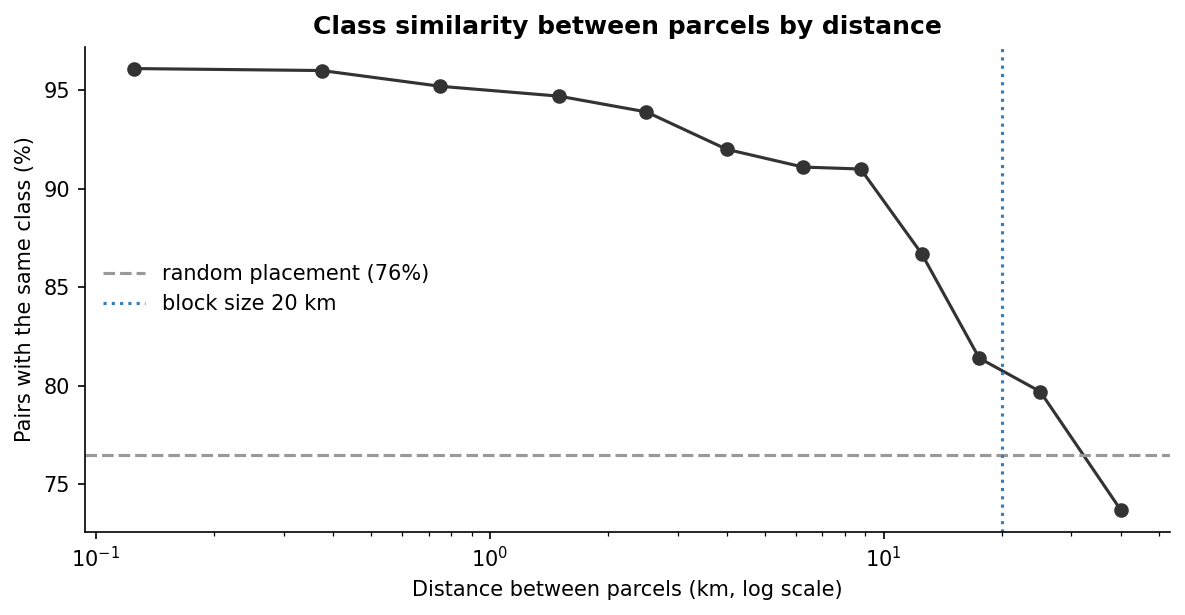

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)
mid = (edges[:-1] + edges[1:]) / 2 / 1000
ax.plot(mid, corr["same class %"], marker="o", color="#333333")
ax.axhline(100 * baseline, color="#999999", linestyle="--", label=f"random placement ({100 * baseline:.0f}%)")
ax.axvline(BLOCK_KM, color=FOLD_COLORS[1], linestyle=":", label=f"block size {BLOCK_KM} km")
ax.set_xscale("log")
ax.set_xlabel("Distance between parcels (km, log scale)")
ax.set_ylabel("Pairs with the same class (%)")
ax.set_title("Class similarity between parcels by distance", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "class_similarity_by_distance.png")
plt.show()

## 2. Choosing the block size

Each candidate block size is turned into 5 balanced folds (method in section 3). For each, the table reports:

- **rainfed in smallest fold**: every fold must hold enough rainfed parcels to score the class;
- **class share range**: how unevenly the classes are spread over folds;
- **test parcels with a training parcel within 250 m / 1 km**, averaged over the 5 test folds: how much leakage remains.

Larger blocks leak less but spread the clustered rainfed parcels unevenly. The random split is the reference.

In [6]:
def block_ids(km):
    size = km * 1000
    bx = np.floor(xy[:, 0] / size).astype(int)
    by = np.floor(xy[:, 1] / size).astype(int)
    return pd.Series(bx).astype(str).values + "_" + pd.Series(by).astype(str).values

def assign_folds(blocks, n_folds=N_FOLDS, seed=RANDOM_SEED):
    # Greedy balancing: blocks with the most rainfed parcels are placed first, each into the fold
    # that is furthest below its share of both classes. Random tie-breaking with a fixed seed.
    table = pd.crosstab(blocks, labels).reindex(columns=[1, 2], fill_value=0)
    rng = np.random.default_rng(seed)
    table = table.loc[rng.permutation(table.index)]
    table = table.sort_values([2, 1], ascending=False, kind="stable")
    totals = table.sum()
    load = np.zeros((n_folds, 2))
    block_fold = {}
    for block, row in table.iterrows():
        after = (load + row.values) / totals.values
        f = int(np.argmin(after.max(axis=1) + 1e-6 * rng.random(n_folds)))
        load[f] += row.values
        block_fold[block] = f
    return pd.Series(blocks).map(block_fold).to_numpy()

def random_folds(n_folds=N_FOLDS, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    folds = np.empty(len(labels), dtype=int)
    for c in (1, 2):
        idx = np.flatnonzero(labels == c)
        rng.shuffle(idx)
        folds[idx] = np.arange(len(idx)) % n_folds
    return folds

def leakage(folds, radius_m):
    shares = []
    for f in range(N_FOLDS):
        test = folds == f
        d, _ = cKDTree(xy[~test]).query(xy[test])
        shares.append((d <= radius_m).mean())
    return 100 * np.mean(shares)

def summarise(name, folds):
    per_fold = pd.crosstab(folds, labels).reindex(columns=[1, 2], fill_value=0)
    share = per_fold / per_fold.sum()
    return {
        "split": name,
        "rainfed in smallest fold": int(per_fold[2].min()),
        "irrigated share range %": f"{100 * share[1].min():.0f}–{100 * share[1].max():.0f}",
        "rainfed share range %": f"{100 * share[2].min():.0f}–{100 * share[2].max():.0f}",
        "test with train ≤250 m %": round(leakage(folds, 250), 1),
        "test with train ≤1 km %": round(leakage(folds, 1000), 1),
    }

rows = [summarise("random", random_folds())]
for km in [2, 5, 10, 20, 25, 30, 50]:
    rows.append(summarise(f"blocks {km} km", assign_folds(block_ids(km))))
block_compare = pd.DataFrame(rows).set_index("split")
block_compare

,rainfed in smallest fold,irrigated share range %,rainfed share range %,test with train ≤250 m %,test with train ≤1 km %
split,,,,,
random,239,20–20,20–20,79.4,98.4
blocks 2 km,239,20–20,20–20,12.8,65.6
blocks 5 km,239,20–20,20–20,6.3,31.7
blocks 10 km,239,20–20,20–20,3.2,18.0
blocks 20 km,238,19–20,20–20,2.0,10.2
blocks 25 km,239,20–20,20–20,1.8,9.1
blocks 30 km,142,1–27,12–34,0.6,4.6
blocks 50 km,202,6–24,17–24,1.2,5.9


**Choice: 20 km blocks.**

- Section 1 shows two scales of dependence. Neighbouring fields (< 1 km) share a class 95% of the time. Beyond that, the similarity stays high out to 20–30 km, because rainfed parcels form one large dryland zone and irrigated parcels sit in large irrigation perimeters. Similarity only nears the random baseline around 20–30 km.
- Blocks up to 25 km still divide the parcels into 5 folds with about 20% of each class in every fold. From 30 km upward, single blocks hold so many rainfed parcels that one fold becomes almost all rainfed. 20 km keeps a safety margin below that limit, and 25 km leaks only slightly less.
- With 20 km blocks only about 2% of test parcels have a training parcel within 250 m, against about 79% with a random split.


## 3. Spatial folds

In [7]:
parcels["block_id"] = block_ids(BLOCK_KM)
parcels["fold"] = assign_folds(parcels["block_id"].to_numpy())
parcels["random_fold"] = random_folds()
parcels["split"] = np.select([parcels["fold"] == TEST_FOLD, parcels["fold"] == VAL_FOLD], ["test", "val"], default="train")

fold_table = pd.crosstab(parcels["fold"], parcels["class_name"]).reindex(columns=CLASSES, fill_value=0)
fold_table["blocks"] = parcels.groupby("fold")["block_id"].nunique()
fold_table["Total"] = fold_table[CLASSES].sum(axis=1)
for c in CLASSES:
    fold_table[f"{c} %"] = (100 * fold_table[c] / fold_table[c].sum()).round(1)
print(f"{parcels['block_id'].nunique()} blocks of {BLOCK_KM} km")
fold_table

91 blocks of 20 km


class_name,Irrigated,Rainfed,blocks,Total,Irrigated %,Rainfed %
fold,,,,,,
0,1528,239,12,1767,20.1,20.0
1,1528,239,13,1767,20.1,20.0
2,1473,241,42,1714,19.4,20.2
3,1528,238,11,1766,20.1,19.9
4,1528,239,13,1767,20.1,20.0


Saved outputs/split/spatial_folds.png


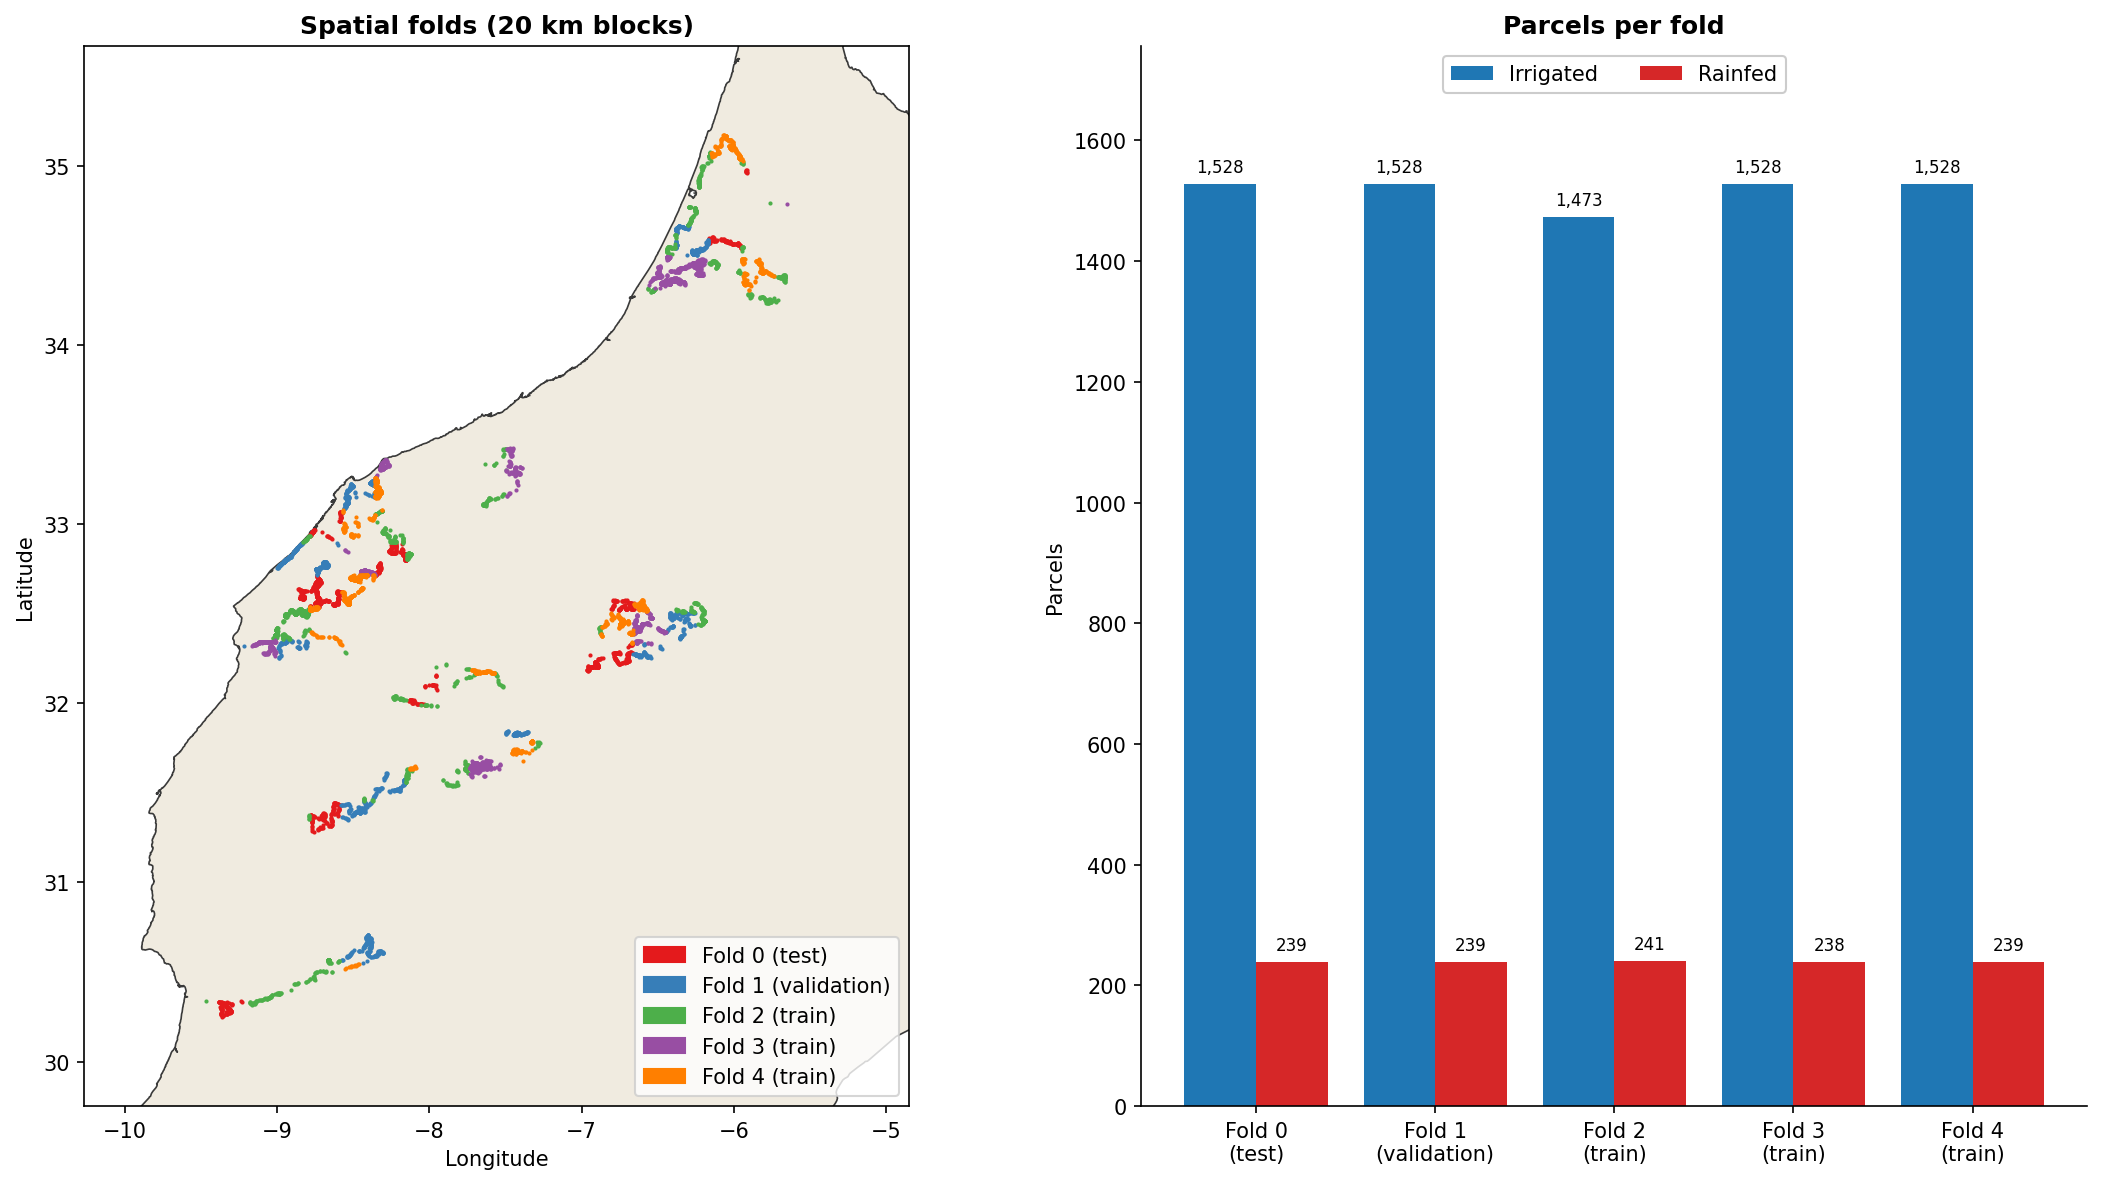

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.3, 1]}, dpi=150)
ax = axes[0]
ll = gpd.GeoSeries(gpd.points_from_xy(parcels["x_utm"], parcels["y_utm"]), crs=UTM).to_crs(4326)
country.plot(ax=ax, facecolor="#f0ebe0", edgecolor="#3a3a3a", linewidth=0.8, zorder=1)
for f in range(N_FOLDS):
    m = parcels["fold"].to_numpy() == f
    ax.scatter(ll.x[m], ll.y[m], s=4, color=FOLD_COLORS[f], linewidths=0, zorder=3)
ax.set_xlim(ll.x.min() - 0.8, ll.x.max() + 0.8)
ax.set_ylim(ll.y.min() - 0.5, ll.y.max() + 0.5)
ROLE = {TEST_FOLD: " (test)", VAL_FOLD: " (validation)"}
ax.legend(handles=[Patch(color=FOLD_COLORS[f], label=f"Fold {f}" + ROLE.get(f, " (train)"))
                   for f in range(N_FOLDS)], loc="lower right")
ax.set_title(f"Spatial folds ({BLOCK_KM} km blocks)", fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax = axes[1]
x = np.arange(N_FOLDS)
ax.bar(x - 0.2, fold_table["Irrigated"], 0.4, color=CLASS_COLORS["Irrigated"], label="Irrigated")
ax.bar(x + 0.2, fold_table["Rainfed"], 0.4, color=CLASS_COLORS["Rainfed"], label="Rainfed")
for i in x:
    ax.text(i - 0.2, fold_table["Irrigated"].iloc[i] + 20, f"{fold_table['Irrigated'].iloc[i]:,}", ha="center", fontsize=8)
    ax.text(i + 0.2, fold_table["Rainfed"].iloc[i] + 20, f"{fold_table['Rainfed'].iloc[i]:,}", ha="center", fontsize=8)
ax.set_xticks(x, [f"Fold {f}" + ROLE.get(f, " (train)").replace(" (", "\n(") for f in x])
ax.set_ylabel("Parcels")
ax.set_title("Parcels per fold", fontweight="bold")
ax.set_ylim(0, fold_table["Irrigated"].max() * 1.15)
ax.legend(loc="upper center", ncol=2, frameon=True, framealpha=1)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "spatial_folds.png")
plt.show()

### The 20 km blocks on the map

Each square is one block, coloured by its fold. Only blocks that contain surveyed parcels are drawn; all parcels in a block share its fold.

91 blocks; parcels per block: median 61, max 455


      blocks  parcels  rainfed
fold                          
0         12     1767      239
1         13     1767      239
2         42     1714      241
3         11     1766      238
4         13     1767      239


Saved outputs/split/spatial_blocks_map.png


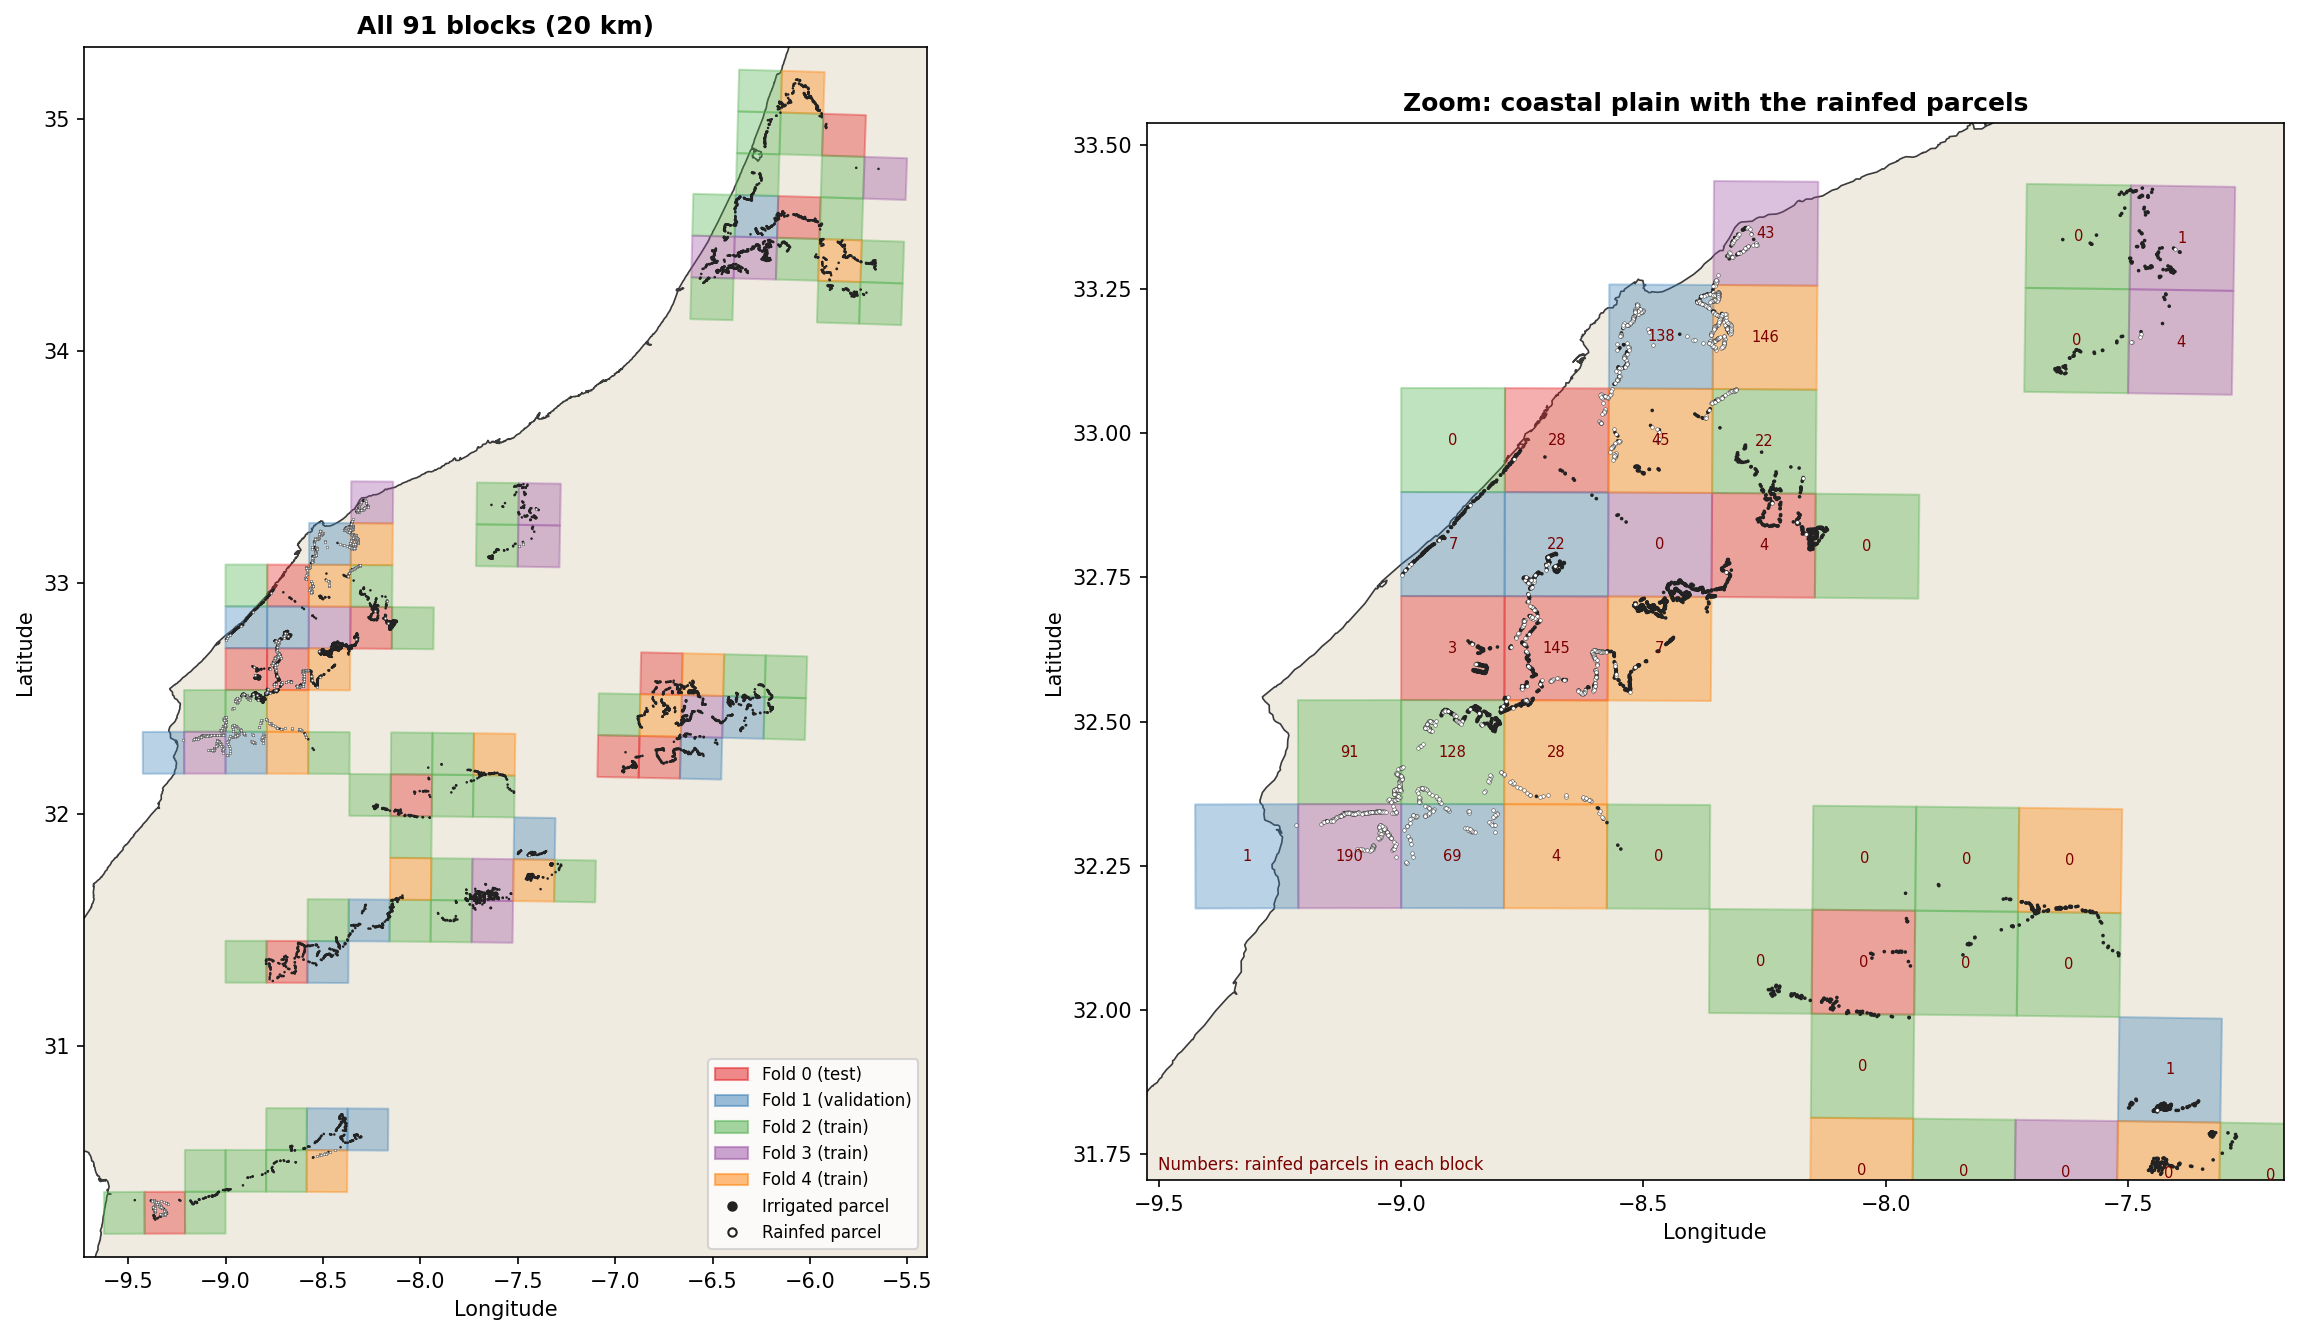

In [9]:
from shapely.geometry import box

size = BLOCK_KM * 1000
blk = parcels.groupby("block_id").agg(fold=("fold", "first"), parcels=("label", "size"),
                                      rainfed=("label", lambda s: int((s == 2).sum())))
ij = blk.index.to_series().str.split("_", expand=True).astype(int)
blocks = gpd.GeoDataFrame(
    blk.reset_index(),
    geometry=[box(i * size, j * size, (i + 1) * size, (j + 1) * size) for i, j in zip(ij[0], ij[1])],
    crs=UTM,
).to_crs(4326)
pts = gpd.GeoSeries(gpd.points_from_xy(parcels["x_utm"], parcels["y_utm"]), crs=UTM).to_crs(4326)
print(f"{len(blocks)} blocks; parcels per block: median {blk['parcels'].median():.0f}, max {blk['parcels'].max()}")
print(blocks.groupby("fold").agg(blocks=("block_id", "size"), parcels=("parcels", "sum"), rainfed=("rainfed", "sum")).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 9), dpi=150)
x0, y0, x1, y1 = blocks.total_bounds
rain_blocks = blocks[blocks["rainfed"] > 0]
rx0, ry0, rx1, ry1 = rain_blocks[rain_blocks.to_crs(UTM).centroid.y > 3_520_000].total_bounds   # north of ~31.8°N
for ax, (bx0, by0, bx1, by1), title in [
    (axes[0], (x0, y0, x1, y1), f"All {len(blocks)} blocks ({BLOCK_KM} km)"),
    (axes[1], (rx0, ry0, rx1, ry1), "Zoom: coastal plain with the rainfed parcels"),
]:
    country.plot(ax=ax, facecolor="#f0ebe0", edgecolor="#3a3a3a", linewidth=0.8, zorder=1)
    for f in range(N_FOLDS):
        blocks[blocks["fold"] == f].plot(ax=ax, facecolor=FOLD_COLORS[f], alpha=0.35,
                                          edgecolor=FOLD_COLORS[f], linewidth=1.0, zorder=2)
    for c in CLASSES:
        m = (parcels["class_name"] == c).to_numpy()
        ax.scatter(pts.x[m], pts.y[m], s=1.5 if ax is axes[0] else 3, color="#222222" if c == "Irrigated" else "#ffffff",
                   edgecolors="#222222" if c == "Rainfed" else "none", linewidths=0.2, zorder=3)
    if ax is axes[1]:
        for _, b in blocks.cx[bx0:bx1, by0:by1].iterrows():
            cx, cy = b.geometry.exterior.coords.xy
            ax.annotate(f"{b['rainfed']}", (np.mean(cx[:4]), np.mean(cy[:4])), ha="center",
                        va="center", fontsize=7, color="#7a0000", zorder=4)
    ax.set_xlim(bx0 - 0.1, bx1 + 0.1)
    ax.set_ylim(by0 - 0.1, by1 + 0.1)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

handles = [Patch(facecolor=FOLD_COLORS[f], alpha=0.5, edgecolor=FOLD_COLORS[f], label=f"Fold {f}" + ROLE.get(f, " (train)"))
           for f in range(N_FOLDS)]
handles += [plt.Line2D([], [], marker="o", linestyle="", color="#222222", markersize=4, label="Irrigated parcel"),
            plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="#ffffff", markeredgecolor="#222222",
                       markersize=4, label="Rainfed parcel")]
axes[0].legend(handles=handles, loc="lower right", fontsize=8)
axes[1].text(0.01, 0.01, "Numbers: rainfed parcels in each block", transform=axes[1].transAxes, fontsize=8, color="#7a0000")
fig.tight_layout()
save(fig, "spatial_blocks_map.png")
plt.show()

Saved outputs/split/spatial_folds_zoom.png


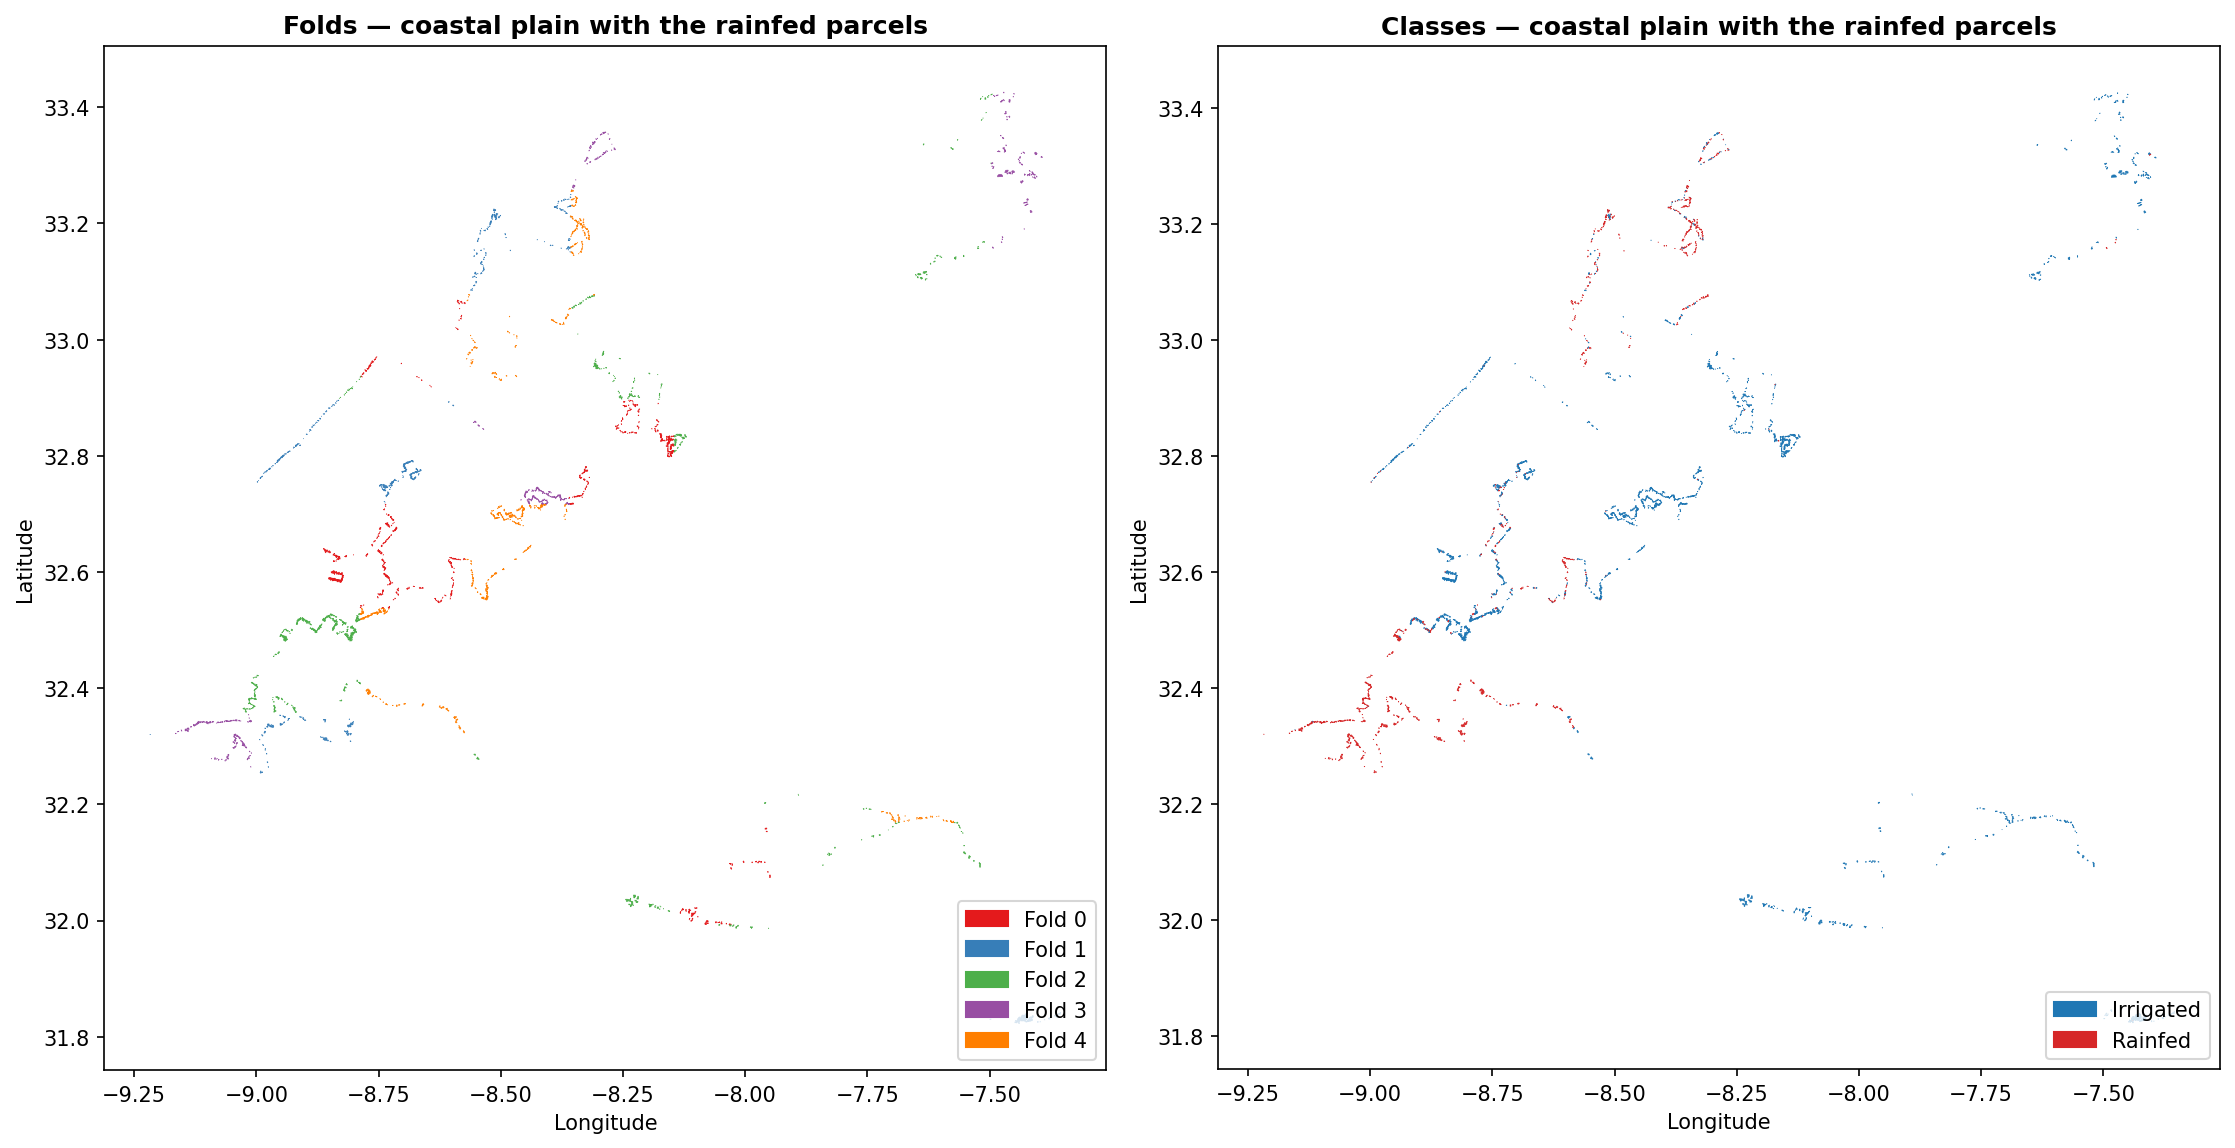

In [10]:
# Zoom on the area with rainfed parcels, where the block structure matters most.
rain = parcels[parcels["label"] == 2].to_crs(4326)
x0, y0, x1, y1 = rain.total_bounds
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), dpi=150)
view = parcels.to_crs(4326).cx[x0 - 0.1 : x1 + 0.1, y0 - 0.1 : y1 + 0.1]
view = view[view["y_utm"] > 3_520_000]          # coastal plain north of ~31.8°N; leaves out the small Souss group
for ax, col, title in [(axes[0], "fold", "Folds"), (axes[1], "class_name", "Classes")]:
    if col == "fold":
        for f in range(N_FOLDS):
            view[view["fold"] == f].plot(ax=ax, color=FOLD_COLORS[f], linewidth=0.3, edgecolor=FOLD_COLORS[f])
        ax.legend(handles=[Patch(color=FOLD_COLORS[f], label=f"Fold {f}") for f in range(N_FOLDS)], loc="lower right")
    else:
        for c in CLASSES:
            view[view["class_name"] == c].plot(ax=ax, color=CLASS_COLORS[c], linewidth=0.3, edgecolor=CLASS_COLORS[c])
        ax.legend(handles=[Patch(color=CLASS_COLORS[c], label=c) for c in CLASSES], loc="lower right")
    ax.set_title(f"{title} — coastal plain with the rainfed parcels", fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.tight_layout()
save(fig, "spatial_folds_zoom.png")
plt.show()

## 4. Default train / validation / test split and leakage check

In [11]:
split_counts = pd.crosstab(parcels["split"], parcels["class_name"]).reindex(index=["train", "val", "test"], columns=CLASSES)
split_counts["Total"] = split_counts.sum(axis=1)
split_counts["share of all %"] = (100 * split_counts["Total"] / len(parcels)).round(1)
split_counts

class_name,Irrigated,Rainfed,Total,share of all %
split,,,,
train,4529,718,5247,59.8
val,1528,239,1767,20.1
test,1528,239,1767,20.1


In [12]:
def dist_to_train(eval_mask, train_mask):
    d, _ = cKDTree(xy[train_mask]).query(xy[eval_mask])
    return d

fold = parcels["fold"].to_numpy()
rfold = parcels["random_fold"].to_numpy()
train_sp = ~np.isin(fold, [TEST_FOLD, VAL_FOLD])
train_rd = ~np.isin(rfold, [TEST_FOLD, VAL_FOLD])
d_spatial = dist_to_train(fold == TEST_FOLD, train_sp)
d_random = dist_to_train(rfold == TEST_FOLD, train_rd)
d_val = dist_to_train(fold == VAL_FOLD, train_sp)
radii = [100, 250, 500, 1000, 5000]
check = pd.DataFrame({
    "test, random split": [100 * (d_random <= r).mean() for r in radii],
    "test, spatial split": [100 * (d_spatial <= r).mean() for r in radii],
    "validation, spatial split": [100 * (d_val <= r).mean() for r in radii],
}, index=[f"train parcel within {r} m" for r in radii]).round(1)
print("Share of test / validation parcels (%) with a training parcel within ...")
check

Share of test / validation parcels (%) with a training parcel within ...


,"test, random split","test, spatial split","validation, spatial split"
train parcel within 100 m,24.1,0.4,0.1
train parcel within 250 m,71.7,1.8,1.1
train parcel within 500 m,90.1,3.8,3.2
train parcel within 1000 m,97.7,8.1,7.1
train parcel within 5000 m,99.7,38.0,28.5


Saved outputs/split/train_test_distance.png


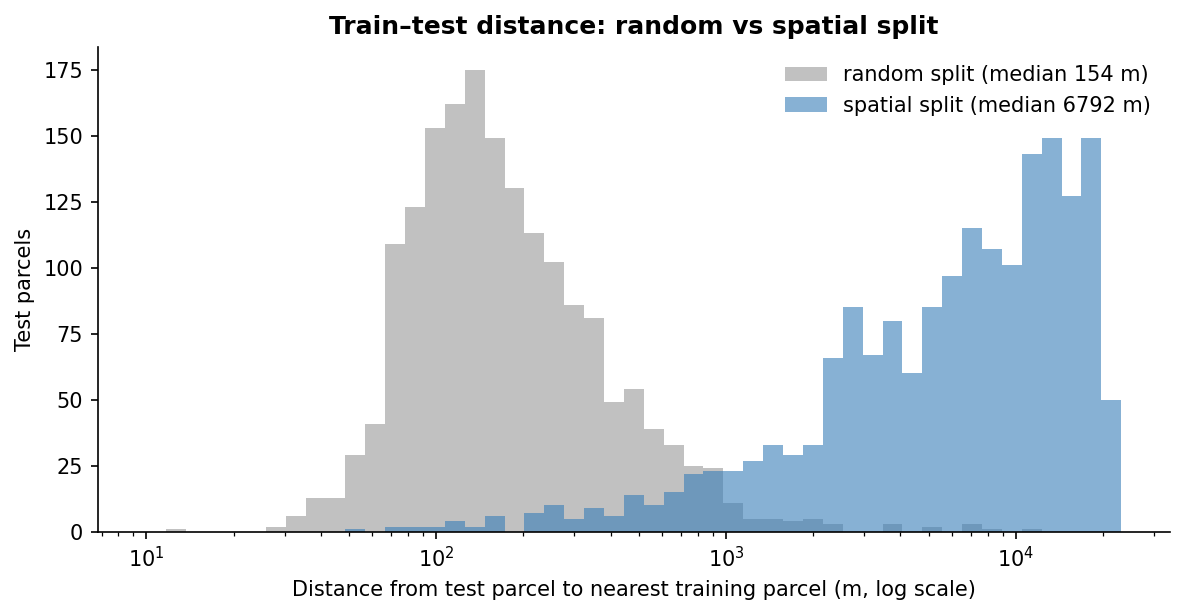

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)
bins = np.logspace(1, np.log10(max(d_spatial.max(), d_random.max())), 50)
ax.hist(d_random, bins=bins, alpha=0.6, color="#999999", label=f"random split (median {np.median(d_random):.0f} m)")
ax.hist(d_spatial, bins=bins, alpha=0.6, color=FOLD_COLORS[1], label=f"spatial split (median {np.median(d_spatial):.0f} m)")
ax.set_xscale("log")
ax.set_xlabel("Distance from test parcel to nearest training parcel (m, log scale)")
ax.set_ylabel("Test parcels")
ax.set_title("Train–test distance: random vs spatial split", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "train_test_distance.png")
plt.show()

## 5. Save

- `parcels_split.geojson`: all parcels with `block_id`, `fold` (spatial, 0–4), `random_fold` (0–4) and `split` (train / test for the default split).
- `train_parcels.geojson`, `val_parcels.geojson`, `test_parcels.geojson`: the default split.

In [14]:
cols = ["parcel_id", "date", "ag_season", "label", "class_name", "area_ha", "block_id", "fold", "random_fold", "split", "geometry"]
out = parcels[cols].copy()
out["date"] = pd.to_datetime(out["date"]).dt.strftime("%Y-%m-%d")

def write(gdf, name):
    # Overwrite the file contents in place.
    path = OUT_DIR / name
    path.write_text(gdf.to_json(drop_id=True))
    print(f"Saved {path.relative_to(ROOT)} ({len(gdf):,} parcels)")

write(out, "parcels_split.geojson")
write(out[out["split"] == "train"], "train_parcels.geojson")
write(out[out["split"] == "val"], "val_parcels.geojson")
write(out[out["split"] == "test"], "test_parcels.geojson")
fold_table.to_csv(OUT_DIR / "fold_counts.csv")
block_compare.to_csv(OUT_DIR / "block_size_comparison.csv")

Saved outputs/split/parcels_split.geojson (8,781 parcels)


Saved outputs/split/train_parcels.geojson (5,247 parcels)
Saved outputs/split/val_parcels.geojson (1,767 parcels)


Saved outputs/split/test_parcels.geojson (1,767 parcels)
